# Smart Supplier — Finite-horizon DP

In [5]:
import numpy as np
import random
import matplotlib.pyplot as plt

In [ ]:
# Environment constants
RM_MAX = 10         # raw material units available each day
DAYS = 5            # planning horizon (days)
MARKET_STATES = [1, 2]   # 1: High Demand A, 2: High Demand B
P_MARKET = {1: 0.5, 2: 0.5}  # next-day market distribution (independent each day)

# Prices by market state
PRICES = {
    1: {"A": 8, "B": 2},   # Market State 1
    2: {"A": 3, "B": 5}    # Market State 2
}

GAMMA = 1.0  # undiscounted finite horizon

# Define discrete action set (action_name : (units_A, units_B))
ACTIONS = {
    0: ("Produce_2A_0B", 2, 0),   # cost = 2*2 = 4 RM
    1: ("Produce_1A_2B", 1, 2),   # cost = 1*2 + 2*1 = 4 RM
    2: ("Produce_0A_5B", 0, 5),   # cost = 5 RM
    3: ("Produce_3A_0B", 3, 0),   # cost = 3*2 = 6 RM
    4: ("Do_Nothing",    0, 0)    # cost = 0
}

# RM cost per product unit
RM_COST = {"A": 2, "B": 1}

In [2]:
def action_cost(units_A, units_B):
    """Return RM cost for a production bundle."""
    return units_A * RM_COST["A"] + units_B * RM_COST["B"]

def immediate_reward_for_action(action_idx, market_state):
    """Return revenue (immediate reward) for executing action in given market state."""
    _, units_A, units_B = ACTIONS[action_idx]
    price_A = PRICES[market_state]["A"]
    price_B = PRICES[market_state]["B"]
    return units_A * price_A + units_B * price_B

def feasible(action_idx, rm_available):
    """Check whether action fits available raw material."""
    _, uA, uB = ACTIONS[action_idx]
    return action_cost(uA, uB) <= rm_available

# Backward induction (finite-horizon DP)
def compute_optimal_policy_and_values(days=DAYS, rm_max=RM_MAX, gamma=GAMMA, p_market=P_MARKET):
    """
    Compute V_t(r,m) and policy π_t(r,m) for t=1..days using backward induction.
    Returns:
      V: numpy array shape (days+2, rm_max+1, num_market_states+1) with V[t][r][m]
         indexing: t in 1..days (we use t index directly), terminal V[days+1] = 0
      policy: numpy array shape (days+1, rm_max+1, max_market_state+1) storing action indices (int)
    """
    max_m = max(MARKET_STATES)
    V = np.zeros((days+2, rm_max+1, max_m+1))       # V[t][r][m], t in 1..days, terminal t=days+1 = 0
    policy = np.zeros((days+1, rm_max+1, max_m+1), dtype=int)  # policy[t][r][m] -> action_idx

    # backward induction: t = days down to 1
    for t in range(days, 0, -1):
        for r in range(rm_max+1):
            for m in MARKET_STATES:
                best_val = -1e12
                best_action = 0
                # evaluate each discrete action
                for a_idx in ACTIONS:
                    name, uA, uB = ACTIONS[a_idx]
                    cost = action_cost(uA, uB)
                    if cost > r:
                        # action fails per spec => no production, reward 0 for day
                        immediate = 0.0
                    else:
                        immediate = immediate_reward_for_action(a_idx, m)

                    # next day's RM resets to rm_max; future value is expectation over next market
                    future = 0.0
                    for m_next, p in p_market.items():
                        future += p * V[t+1][rm_max][m_next]

                    q = immediate + gamma * future

                    # deterministic tie-breaker: prefer higher immediate reward (or smaller index)
                    if q > best_val or (np.isclose(q, best_val) and immediate > immediate_reward_for_action(best_action, m)):
                        best_val = q
                        best_action = a_idx

                V[t][r][m] = best_val
                policy[t][r][m] = best_action
    return V, policy

# Simulation utilities
def simulate_policy(policy, n_episodes=1000, days=DAYS, rm_max=RM_MAX, p_market=P_MARKET, seed=None):
    """
    Simulate the multi-day process following given policy.
    policy: array policy[t][r][m] (t from 1..days)
    Returns average total profit across episodes and distribution list.
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    totals = []
    for ep in range(n_episodes):
        total_profit = 0.0
        for t in range(1, days+1):
            # sample current market
            m = 1 if random.random() < p_market[1] else 2
            r = rm_max
            a_idx = int(policy[t][r][m])
            # check feasibility
            _, uA, uB = ACTIONS[a_idx]
            cost = action_cost(uA, uB)
            if cost > r:
                # action fails: reward = 0
                reward = 0.0
            else:
                reward = immediate_reward_for_action(a_idx, m)
            total_profit += reward
            # next day: RM resets (handled by loop)
        totals.append(total_profit)
    return np.mean(totals), totals

def simulate_greedy_baseline(n_episodes=1000, days=DAYS, rm_max=RM_MAX, p_market=P_MARKET, seed=None):
    """
    Greedy baseline: each day produce the feasible action that gives max immediate reward
    for the observed market state (no planning across days).
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    totals = []
    for ep in range(n_episodes):
        total_profit = 0.0
        for t in range(1, days+1):
            m = 1 if random.random() < p_market[1] else 2
            best_rwd = -1e9
            best_action = 4  # default Do_Nothing
            for a_idx in ACTIONS:
                if feasible(a_idx, rm_max):
                    rwd = immediate_reward_for_action(a_idx, m)
                else:
                    rwd = -1e9
                if rwd > best_rwd:
                    best_rwd = rwd
                    best_action = a_idx
            # execute chosen action (feasible by construction)
            if best_rwd < 0:
                reward = 0
            else:
                reward = max(0, best_rwd)
            total_profit += reward
        totals.append(total_profit)
    return np.mean(totals), totals


In [7]:
# Visualizations
def action_label(a_idx):
    return ACTIONS[a_idx][0]

def plot_policy_heatmaps(policy, days=DAYS, rm_max=RM_MAX):
    """
    For each day, plot a heatmap: x-axis RM (0..rm_max), y-axis market state (1..2),
    colors represent actions chosen (mapped to integers).
    """
    import matplotlib.colors as mcolors

    n_actions = len(ACTIONS)
    cmap = plt.get_cmap("tab10", n_actions)
    action_names = [ACTIONS[i][0] for i in range(n_actions)]

    fig, axes = plt.subplots(1, days, figsize=(3*days, 4), constrained_layout=True)
    if days == 1:
        axes = [axes]
    for t in range(1, days+1):
        grid = np.zeros((len(MARKET_STATES), rm_max+1), dtype=int)
        for i, m in enumerate(MARKET_STATES):
            for r in range(rm_max+1):
                grid[i, r] = policy[t][r][m]
        ax = axes[t-1]
        im = ax.imshow(grid, aspect='auto', origin='lower', cmap=cmap, vmin=0, vmax=n_actions-1)
        ax.set_title(f"Day {t}")
        ax.set_xlabel("Raw Material (r)")
        ax.set_ylabel("Market State (1:HighA, 2:HighB)")
        ax.set_yticks([0,1])
        ax.set_yticklabels([str(m) for m in MARKET_STATES])
        ax.set_xticks(range(0, rm_max+1, max(1, rm_max//5)))
        # annotate with action short labels
        for (i_row, j_col), val in np.ndenumerate(grid):
            ax.text(j_col, i_row, f"{val}", va='center', ha='center', fontsize=6, color='white' if val%2==0 else 'black')
    cbar = fig.colorbar(im, ax=axes, ticks=list(range(n_actions)))
    cbar.ax.set_yticklabels(action_names)
    plt.show()

def plot_value_progression(V, days=DAYS, rm_max=RM_MAX):
    """
    Plot V_t(rm=rm_max, m) across days (start-of-day values).
    """
    days_range = list(range(1, days+1))
    v_state1 = [V[t][rm_max][1] for t in days_range]
    v_state2 = [V[t][rm_max][2] for t in days_range]

    plt.figure(figsize=(8,4))
    plt.plot(days_range, v_state1, marker='o', label="Start Day Value (Market=1)")
    plt.plot(days_range, v_state2, marker='o', label="Start Day Value (Market=2)")
    plt.gca().invert_xaxis()  # optional: show day 1 left, day T right, but invert to show backward induction
    plt.xlabel("Day (t)")
    plt.ylabel(f"V_t(r={rm_max}, m)")
    plt.title("Value progression across days (start-of-day values)")
    plt.grid(True)
    plt.legend()
    plt.show()

def plot_policy_bar_for_day(policy, day=1, m=1, rm_max=RM_MAX):
    """
    Bar plot showing how action choice varies with RM for one day and market state.
    """
    action_idxs = [policy[day][r][m] for r in range(rm_max+1)]
    plt.figure(figsize=(10,2))
    plt.bar(range(rm_max+1), action_idxs)
    plt.xlabel("Raw Material (r)")
    plt.ylabel("Action Index")
    plt.title(f"Day {day}, Market {m}: Action index vs RM  (labels below)")
    plt.xticks(range(0, rm_max+1, max(1, rm_max//10)))
    plt.yticks(list(ACTIONS.keys()), [ACTIONS[i][0] for i in ACTIONS])
    plt.show()

Computed optimal finite-horizon V and policy.

Sample V_t at start (r=RM_MAX) for each day and market state:
 Day 1: V[1][r=10][m=1] = 122.00, V[1][r=10][m=2] = 123.00
 Day 2: V[2][r=10][m=1] = 97.50, V[2][r=10][m=2] = 98.50
 Day 3: V[3][r=10][m=1] = 73.00, V[3][r=10][m=2] = 74.00
 Day 4: V[4][r=10][m=1] = 48.50, V[4][r=10][m=2] = 49.50
 Day 5: V[5][r=10][m=1] = 24.00, V[5][r=10][m=2] = 25.00

Sample policy snapshot (Day 1, r values 0..10):
 r= 0 -> Produce_2A_0B
 r= 1 -> Produce_2A_0B
 r= 2 -> Produce_2A_0B
 r= 3 -> Produce_2A_0B
 r= 4 -> Produce_2A_0B
 r= 5 -> Produce_2A_0B
 r= 6 -> Produce_3A_0B
 r= 7 -> Produce_3A_0B
 r= 8 -> Produce_3A_0B
 r= 9 -> Produce_3A_0B
 r=10 -> Produce_3A_0B

Simulated learned policy over 5000 episodes -> Avg total profit: $122.50
Simulated greedy baseline over 5000 episodes -> Avg total profit: $122.50

Plotting policy heatmaps (each day).


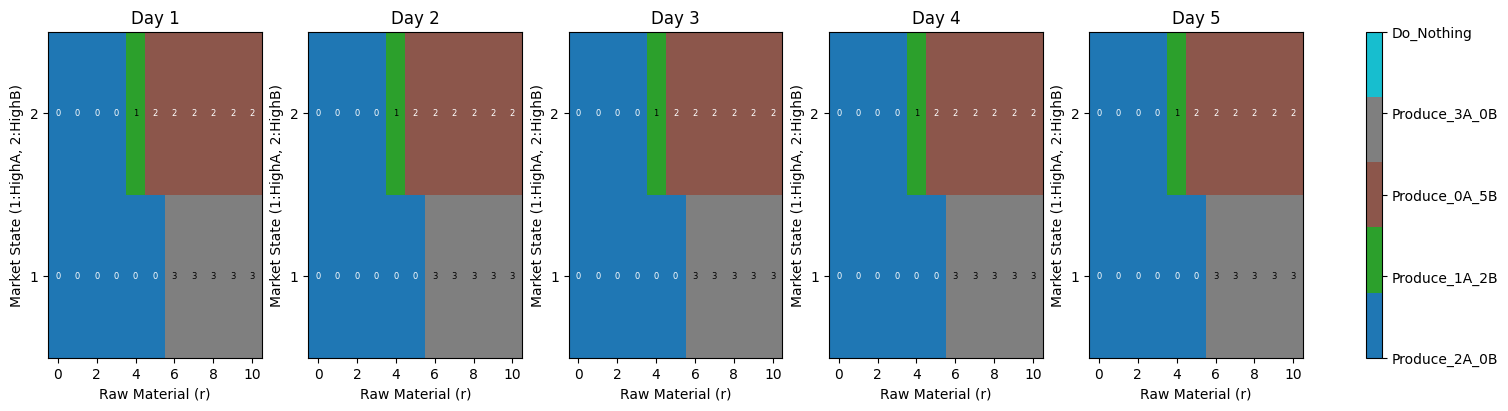

Plotting value progression for start-of-day (r=RM_MAX).


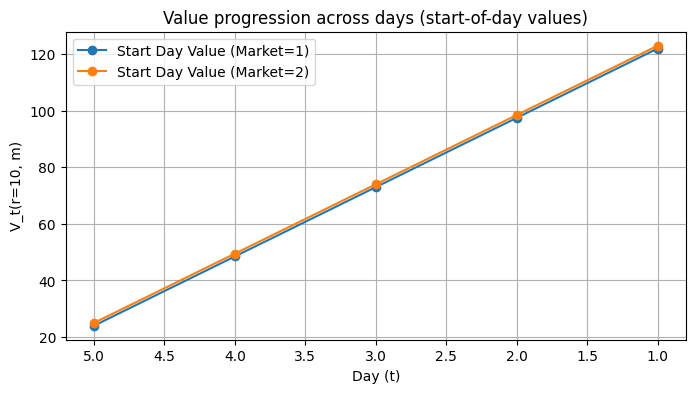

Plot action index vs RM for Day 1, Market 1 (example).


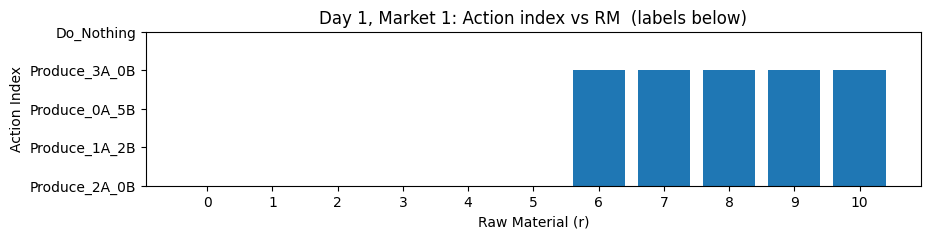


Recomputing DP assuming market is always State 1 (deterministic), for comparison.
Avg profit if market always State 1 (5000 sims): $120.00


In [8]:
# Main: compute, simulate, visualize, compare
if __name__ == "__main__":
    # 1) Compute optimal values & policy
    V, policy = compute_optimal_policy_and_values(days=DAYS, rm_max=RM_MAX, gamma=GAMMA, p_market=P_MARKET)
    print("Computed optimal finite-horizon V and policy.")

    # 2) Print some key values and sample policy decisions
    print("\nSample V_t at start (r=RM_MAX) for each day and market state:")
    for t in range(1, DAYS+1):
        print(f" Day {t}: V[{t}][r={RM_MAX}][m=1] = {V[t][RM_MAX][1]:.2f}, V[{t}][r={RM_MAX}][m=2] = {V[t][RM_MAX][2]:.2f}")

    print("\nSample policy snapshot (Day 1, r values 0..10):")
    for r in range(RM_MAX+1):
        a_idx = policy[1][r][1]  # market state 1 example
        print(f" r={r:2d} -> {ACTIONS[a_idx][0]}")

    # 3) Simulate learned policy
    mean_profit, profits = simulate_policy(policy, n_episodes=5000, days=DAYS, rm_max=RM_MAX, p_market=P_MARKET, seed=42)
    print(f"\nSimulated learned policy over 5000 episodes -> Avg total profit: ${mean_profit:.2f}")

    # 4) Simulate greedy baseline
    mean_greedy, greedy_profits = simulate_greedy_baseline(n_episodes=5000, days=DAYS, rm_max=RM_MAX, p_market=P_MARKET, seed=42)
    print(f"Simulated greedy baseline over 5000 episodes -> Avg total profit: ${mean_greedy:.2f}")

    # 5) Visualizations
    print("\nPlotting policy heatmaps (each day).")
    plot_policy_heatmaps(policy, days=DAYS, rm_max=RM_MAX)

    print("Plotting value progression for start-of-day (r=RM_MAX).")
    plot_value_progression(V, days=DAYS, rm_max=RM_MAX)

    print("Plot action index vs RM for Day 1, Market 1 (example).")
    plot_policy_bar_for_day(policy, day=1, m=1, rm_max=RM_MAX)

    # 6) Analysis examples: Compare to fixed-market scenario (always market state 1)
    print("\nRecomputing DP assuming market is always State 1 (deterministic), for comparison.")
    V_fix, policy_fix = compute_optimal_policy_and_values(days=DAYS, rm_max=RM_MAX, gamma=GAMMA, p_market={1:1.0, 2:0.0})
    mean_fix, _ = simulate_policy(policy_fix, n_episodes=5000, days=DAYS, rm_max=RM_MAX, p_market={1:1.0, 2:0.0}, seed=42)
    print(f"Avg profit if market always State 1 (5000 sims): ${mean_fix:.2f}")